# 04 · Phase 4: Model comparison (RQ2) and number of early cycles (RQ4)

**Questions.** Do model types other than the paper's elastic net do better with 41 training cells (RQ2)? Do our F4
features help them too (RQ3, part 2)? How does the error depend on the number of early cycles N (RQ4)?

**Models** (no trees or neural networks: with 41 cells they can memorise the training set, and trees cannot predict
outside the training life range):

| Model | Different from the paper because… |
|---|---|
| PLS | uses the whole ΔQ(V) curve, not summary statistics |
| Gaussian process (GP) | non-linear, gives a prediction interval |
| SVR (RBF) | non-linear, robust loss |
| Additive splines (GAM) | one smooth curve per feature |

**Protocol.** Every variant and setting was chosen by nested cross-validation on the **training cells only**; every
registered configuration was evaluated **once** on the test sets and all are reported. The unseen batch is not used.

**Prerequisites** (repo root; ~2 + ~10 + ~1 min):
```
python3 -m src.p4_pls && python3 -m src.p4_models && python3 -m src.horizon
```

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from IPython.display import Image, display
from config import RESULTS_DIR, VDLIN
from src.features import load_features, FEATURE_SETS
from src.models import make_regressor, gp_predict_std
from src.pls import design_matrix, make_pls, bin_voltages

%matplotlib inline
mpl.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "font.size": 9})
pd.set_option("display.width", 200, "display.max_columns", 30)
warnings.filterwarnings("ignore")
P = json.load(open(RESULTS_DIR / "p4_pls.json"))
M = json.load(open(RESULTS_DIR / "p4_models.json"))
H = json.load(open(RESULTS_DIR / "horizon.json"))
df = load_features(); tr = df[df.split == "train"]; paper = df[df.split != "unseen"]
FIG = ROOT / "report" / "figures"
print("pre-registered:", P["preregistered"], M["preregistered"])

pre-registered: {'primary': 'asinh', 'secondary': 'f4_shape'} {'models': ['gp', 'svr', 'gam'], 'feature_sets': ['discharge', 'physics']}


## 1 · PLS on the whole ΔQ curve
Life follows a power law in the ΔQ amplitude, PLS is linear in its inputs, so four input versions were compared on
the training cells (nested CV, identical folds). In the block versions each block gets a CV-chosen share of the variance.

In [2]:
pd.Series({k: v["rmse_log"] for k, v in P["nested_cv_train"].items()}, name="nested-CV RMSE log10").round(4).to_frame()

,nested-CV RMSE log10
PLS raw,0.0892
PLS asinh,0.0684
PLS amp_shape,0.0706
PLS f4_shape,0.0543
OLS log sd(ΔQ),0.0723
OLS F4,0.0501
EN discharge (F2),0.0578
EN F4,0.0507


The shape adds almost nothing beyond the amplitude, and adding it to F4 makes things worse. The best whole-curve model
(asinh) and F4 + shape were then evaluated once on the test sets:

In [3]:
rows = {}
for k in ("pls_asinh", "pls_f4_shape", "en_discharge", "en_physics"):
    v = P["test"][k]; s = v["scores"]
    rows[k] = {q: f"{s[q]['rmse']:.0f} / {s[q]['mape']:.1f}%" for q in ("train", "primary", "primary_excl", "secondary")}
    rows[k]["primary in range"] = f"{v['robust']['primary']['rmse_in_range']:.0f}"
pd.DataFrame(rows).T

,train,primary,primary_excl,secondary,primary in range
pls_asinh,65 / 8.6%,138 / 18.5%,128 / 12.9%,3431 / 99.2%,104
pls_f4_shape,55 / 7.2%,151 / 10.5%,152 / 8.6%,285 / 21.7%,117
en_discharge,69 / 9.2%,90 / 12.6%,85 / 9.4%,167 / 9.9%,86
en_physics,67 / 8.8%,114 / 9.9%,115 / 9.1%,170 / 11.1%,75


**Why PLS fails on the secondary batch.** It puts a large, narrow weight near 3.15 V, the steep edge where the plateau
starts. In the secondary batch that edge sits at a different voltage (different procedure: 5-s rests), which alone raises
the predictions by a factor of ~2.2. Recomputed live:

3.25-3.50 V: mean input train -0.18, secondary -0.00 -> shift in predicted log10 life -0.036
3.10-3.25 V: mean input train -3.02, secondary -1.89 -> shift in predicted log10 life +0.335
2.90-3.10 V: mean input train -4.41, secondary -3.80 -> shift in predicted log10 life -0.097
2.50-2.90 V: mean input train -4.12, secondary -3.57 -> shift in predicted log10 life +0.237
2.00-2.50 V: mean input train -3.26, secondary -2.69 -> shift in predicted log10 life -0.064


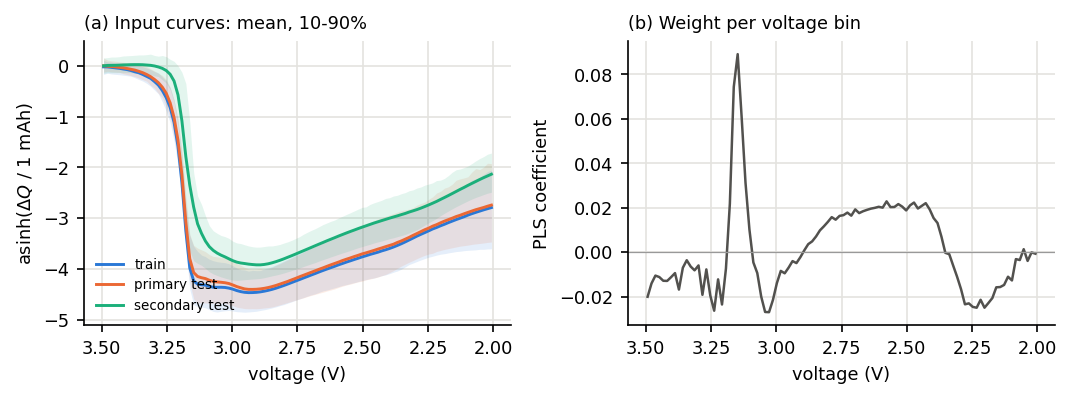

In [4]:
y = np.log10(tr.cycle_life.to_numpy())
gs = make_pls("asinh").fit(design_matrix(tr, "asinh"), y)
V = bin_voltages(VDLIN); coef = np.ravel(gs.best_estimator_.pls_.coef_)
Xt, Xs = design_matrix(tr, "asinh"), design_matrix(df[df.split == "secondary_test"], "asinh")
for lo, hi in ((3.25, 3.5), (3.1, 3.25), (2.9, 3.1), (2.5, 2.9), (2.0, 2.5)):
    m = (V >= lo) & (V < hi)
    print(f"{lo:.2f}-{hi:.2f} V: mean input train {Xt[:, m].mean():+.2f}, secondary {Xs[:, m].mean():+.2f} -> "
          f"shift in predicted log10 life {(coef[m] * (Xs[:, m].mean(0) - Xt[:, m].mean(0))).sum():+.3f}")
display(Image(str(FIG / "fig_p4_pls.png"), width=760))

## 2 · Gaussian process, SVR and additive splines on F2 and F4
GP kernel: linear + Matérn (one length-scale per feature) + noise. Unbounded it interpolated the 41 training cells
exactly, so two bounds were set on the training cells: length-scales ≥ 1 SD and a noise floor (~4% of life).
A screened extra feature (voltage drop at fixed charge) was rejected first: ρ = 0.99 with ΔQ variance, no gain.

In [5]:
T = M["test"]; cv = M["nested_cv_train"]
rows = {}
for k, v in T.items():
    if k in ("bootstrap", "predictions"):
        continue
    s, r = v["scores"], v["robust"]
    rows[k] = {"nested CV log10": round(cv[k]["rmse_log"], 4),
               **{q: f"{s[q]['rmse']:.0f} / {s[q]['mape']:.1f}%" for q in ("primary", "primary_excl", "secondary")},
               "in range": round(r["primary"]["rmse_in_range"]),
               "GP 95% coverage prim/sec": (f"{v['coverage_95']['primary']:.2f} / {v['coverage_95']['secondary']:.2f}" if "coverage_95" in v else "")}
pd.DataFrame(rows).T

,nested CV log10,primary,primary_excl,secondary,in range,GP 95% coverage prim/sec
gp_discharge,0.065,85 / 11.4%,79 / 8.1%,174 / 10.5%,78,0.81 / 0.95
svr_discharge,0.0677,176 / 12.6%,174 / 9.1%,169 / 9.7%,65,
gam_discharge,0.0776,242 / 10.6%,243 / 8.6%,169 / 14.5%,79,
gp_physics,0.0478,103 / 7.9%,103 / 6.6%,180 / 11.4%,64,0.95 / 0.85
svr_physics,0.0576,107 / 9.3%,107 / 8.0%,190 / 14.9%,76,
gam_physics,0.0593,92 / 8.3%,92 / 6.9%,207 / 16.3%,66,
en_discharge,0.0578,90 / 12.6%,85 / 9.4%,167 / 9.9%,86,
en_physics,0.0507,114 / 9.9%,115 / 9.1%,170 / 11.1%,75,


In [6]:
# paired bootstrap vs the elastic net on the same features, identical in-range cells (negative = better)
for key, b in T["bootstrap"].items():
    print(key)
    for pair, w in b.items():
        if "-" in pair:
            flag = "  *" if w["rmse_ci"][1] < 0 or w["rmse_ci"][0] > 0 else ""
            print(f"   {pair:28s} {w['rmse_diff']:+5.0f}  [{w['rmse_ci'][0]:+.0f}, {w['rmse_ci'][1]:+.0f}]{flag}")

primary
   gp_discharge-en_discharge       -7  [-35, +19]
   svr_discharge-en_discharge     -20  [-49, -3]  *
   gam_discharge-en_discharge      -8  [-28, +14]
   gp_physics-en_physics          -11  [-21, -3]  *
   svr_physics-en_physics          -0  [-16, +17]
   gam_physics-en_physics         -10  [-24, +2]
secondary
   gp_discharge-en_discharge       +8  [-4, +22]
   svr_discharge-en_discharge      +1  [-9, +9]
   gam_discharge-en_discharge      +3  [-48, +58]
   gp_physics-en_physics           +9  [-1, +17]
   svr_physics-en_physics         +22  [-15, +60]
   gam_physics-en_physics         +39  [-16, +95]


,b1c2,b2c1,observed
en_discharge,2192.0,360.0,2237 / 148
gp_discharge,2341.0,367.0,2237 / 148
svr_discharge,1186.0,388.0,2237 / 148
gam_discharge,742.0,291.0,2237 / 148
en_physics,1667.0,212.0,2237 / 148
gp_physics,1708.0,243.0,2237 / 148
svr_physics,1741.0,244.0,2237 / 148
gam_physics,1820.0,246.0,2237 / 148


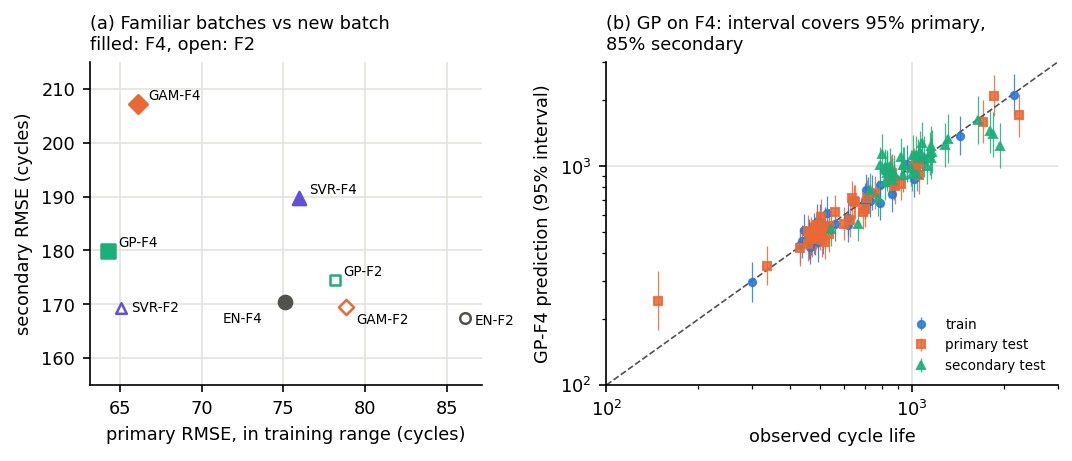

In [7]:
# the two primary cells outside the training life range (300-2160 cycles)
pred = pd.DataFrame(T["predictions"])
display(pred.loc[["b1c2", "b2c1"]].round(0).T.assign(observed=lambda d: "2237 / 148"))
display(Image(str(FIG / "fig_p4_models.png"), width=760))

**Reading it.** Within the training batches the non-linear models help (GP-F4 and SVR-F2 significantly, on in-range
primary cells). On the new batch none is better than the elastic net, and the flexible ones are worse. SVR and the
spline model break for the longest-lived cell (b1c2: 1186 and 742 for F2), because they have no linear backbone.
The GP on F4 gives calibrated 95% intervals on the primary set (95%) but is overconfident on the new batch (85%).

## 3 · Number of early cycles (RQ4)
Features recomputed from cycles ≤ N, models re-tuned at every N; b2c1 (life 148) excluded from the primary scores.

,20,30,40,50,60,80,100,150
discharge,399 / 511,306 / 350,191 / 182,1829 / 1186,428 / 439,169 / 209,85 / 167,82 / 199
full,233 / 396,205 / 345,157 / 212,168 / 247,142 / 230,146 / 213,122 / 220,103 / 224
physics,399 / 511,309 / 304,202 / 252,186 / 255,218 / 238,208 / 223,115 / 170,114 / 177
gp_physics,357 / 428,311 / 298,202 / 248,167 / 270,203 / 260,190 / 221,103 / 180,82 / 194
life used,3%,4%,5%,7%,8%,11%,14%,20%


GP-F4 minus EN-F4 (negative = GP better):
  N= 20  primary   -46 [-95,-6]   secondary   -83 [-113,-55]
  N= 30  primary    +1 [-4,+7]   secondary    -7 [-20,+4]
  N= 40  primary    -0 [-2,+1]   secondary    -4 [-6,-2]
  N= 50  primary   -17 [-47,+14]   secondary   +13 [-15,+38]
  N= 60  primary   -14 [-24,-1]   secondary   +23 [+10,+35]
  N= 80  primary   -16 [-28,+1]   secondary    -2 [-15,+12]
  N=100  primary   -12 [-19,-5]   secondary    +9 [-0,+17]
  N=150  primary   -30 [-58,-1]   secondary   +17 [+12,+21]


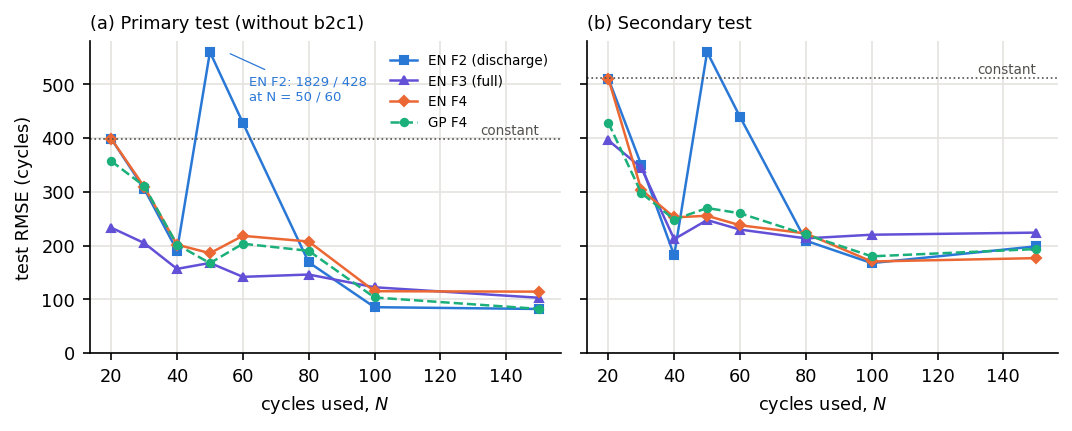

In [8]:
ns = sorted(int(n) for n in H["horizons"])
tab = {}
for m in ("discharge", "full", "physics", "gp_physics"):
    tab[m] = {n: f"{H['horizons'][str(n)]['models'][m]['primary_excl']['rmse']:.0f} / {H['horizons'][str(n)]['models'][m]['secondary']['rmse']:.0f}"
              for n in ns}
t = pd.DataFrame(tab).T
t.loc["life used"] = {n: f"{100 * H['horizons'][str(n)]['median_fraction_of_life_used']:.0f}%" for n in ns}
display(t)
print("GP-F4 minus EN-F4 (negative = GP better):")
for n, v in H["gp_vs_en_physics"].items():
    print(f"  N={n:>3s}  primary {v['primary_excl']['diff']:+5.0f} [{v['primary_excl']['ci'][0]:+.0f},{v['primary_excl']['ci'][1]:+.0f}]"
          f"   secondary {v['secondary']['diff']:+5.0f} [{v['secondary']['ci'][0]:+.0f},{v['secondary']['ci'][1]:+.0f}]")
display(Image(str(FIG / "fig_p4_horizon.png"), width=760))

* Below ~30 cycles ΔQ has no signal; only policy/batch information (full model) predicts that early.
* 40–80 cycles: about half the constant-baseline error. 100 cycles: clearly better. Beyond 100: no gain.
* The paper's log|min ΔQ| feature is fragile when ΔQ is near zero (N = 50: a predicted life of 13,393 cycles for b1c0);
  F4 (a standard deviation) is not.

## 4 · Answers
* **RQ2.** No model beats the paper's linear model on a new batch. Non-linear models help within the training batches;
  models without a linear backbone fail outside the training range; whole-curve PLS fails on the new batch. The most
  useful alternative is the GP on F4 (best within the training batches, calibrated intervals there).
* **RQ3, part 2.** With every model except SVR, F4 gives the better within-batch result; on the new batch F2 stays slightly better.
* **RQ4.** ~40 cycles for a rough screen, 100 cycles clearly better, nothing gained beyond 100.
* **Caveat.** Many configurations have now been evaluated on the same ~40 test cells; only bootstrap-resolved
  differences should be relied on.